# ACT, built forward

Same data, split and eval seeds as `bc_2.ipynb`. BC there: 0–3/20 per run. Repo ACT: 49/60.

### step 0 — the data, as in BC

In [1]:
from pathlib import Path

import numpy as np
from lerobot.datasets.lerobot_dataset import LeRobotDataset

np.set_printoptions(precision=3, suppress=True)
REPO = Path.cwd().parent
ds = LeRobotDataset("dream_robot/pick_place_cube", root=REPO / "data/robosuite/pick_place_cube")

# as bc_2 steps 1, 2 and 4: straight from the table, same 5 held-out demos
state = np.asarray(ds.hf_dataset["observation.state"], dtype=np.float32)  # [N, 8]
action = np.asarray(ds.hf_dataset["action"], dtype=np.float32)  # [N, 8]
episode = np.asarray(ds.hf_dataset["episode_index"])  # [N], which demo each frame is from
val_eps = np.random.default_rng(0).permutation(25)[:5]
is_val = np.isin(episode, val_eps)  # [N]
print(f"{state.shape=}  {action.shape=}  {val_eps=}  train {(~is_val).sum()}  val {is_val.sum()}")

/home/rahul/Documents/codes/ml/dream-robot/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


state.shape=(5288, 8)  action.shape=(5288, 8)  val_eps=array([19,  4, 10, 11, 24])  train 4218  val 1070


### step 1 — the target is a chunk: the next K actions, not one

In [2]:
K = 50  # chunk length: 50 steps = 1.7 s at 30 Hz; a demo is ~210 steps
N = len(action)

# last row of each frame's demo. Demos are stored one after another in order,
# so demo e's last row is where its run of rows ends
assert (np.diff(episode) >= 0).all(), "demos not stored in order"
last = np.searchsorted(episode, episode, side="right") - 1  # [N]

idx = np.arange(N)[:, None] + np.arange(K)  # [N, K], rows t .. t+K-1
pad = idx > last[:, None]  # [N, K], True where the chunk runs past its demo's end
idx = np.minimum(idx, last[:, None])  # [N, K], past the end: repeat the final action
chunks = action[idx]  # [N, K, 8]
print(f"{chunks.shape=}  {pad.shape=}")
print(f"frames whose chunk is partly padding: {pad.any(1).sum()} of {N}")

chunks.shape=(5288, 50, 8)  pad.shape=(5288, 50)
frames whose chunk is partly padding: 1225 of 5288


### step 2 — what a chunk looks like

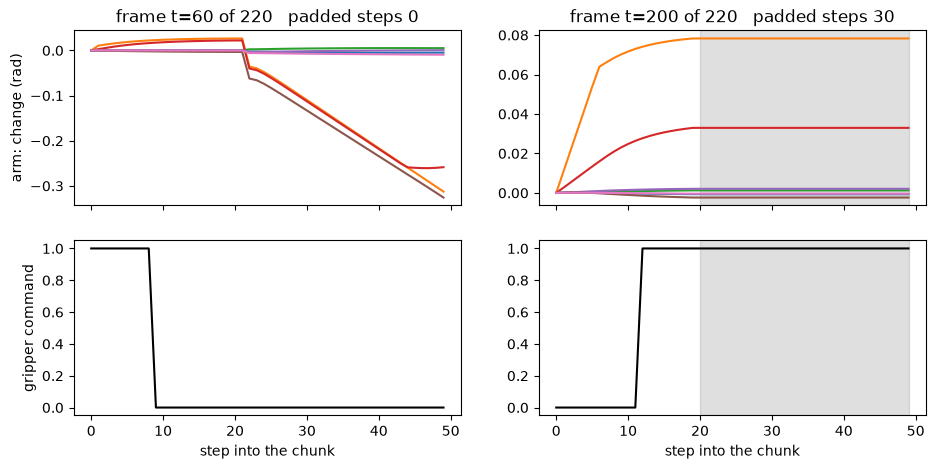

In [4]:
import matplotlib.pyplot as plt

rows = np.flatnonzero(episode == 2)  # demo 2's frames, as in bc_2
fig, ax = plt.subplots(2, 2, figsize=(11, 5), sharex=True)
for col, t in enumerate([60, len(rows) - 20]):  # mid-demo, and 20 steps before the end
    ch = chunks[rows[t]]  # [K, 8], the plan from frame t
    ax[0, col].plot(ch[:, :7] - ch[0, :7])  # 7 arm joints, as change from the chunk's first action
    ax[1, col].plot(ch[:, 7], color="k")  # gripper command: 1 open, 0 close
    n_pad = pad[rows[t]].sum()
    if n_pad:
        for a in ax[:, col]:
            a.axvspan(K - n_pad, K - 1, color="grey", alpha=0.25)  # padded: repeats the final action
    ax[0, col].set_title(f"frame t={t} of {len(rows)}   padded steps {n_pad}")
    ax[1, col].set_xlabel("step into the chunk")
ax[0, 0].set_ylabel("arm: change (rad)")
ax[1, 0].set_ylabel("gripper command")
plt.show()

### step 3 — both cameras into RAM (~20 s)

In [5]:
import torch
from torch import Tensor, nn

# both cameras into RAM once, as uint8 (~20 s), as bc_2 steps 8 and 21
cams = ["top", "wrist"]
ims = {cam: np.zeros((N, 3, 128, 128), dtype=np.uint8) for cam in cams}  # {cam: [N, 3, H, W]}
for i in range(N):
    item = ds[i]  # decodes this frame from both videos
    for cam in cams:
        ims[cam][i] = (item[f"observation.images.{cam}"] * 255).round().to(torch.uint8).numpy()
print({cam: im.shape for cam, im in ims.items()})

{'top': (5288, 3, 128, 128), 'wrist': (5288, 3, 128, 128)}


### step 4 — to the GPU, plus normalisation stats

In [6]:
dev = "cuda"
tr, va = ~is_val, is_val
# everything on the GPU, split once; images stay uint8 until a batch is drawn
IM = {cam: (torch.tensor(ims[cam][tr]).to(dev), torch.tensor(ims[cam][va]).to(dev)) for cam in cams}
Xtr, Xva = torch.tensor(state[tr]).to(dev), torch.tensor(state[va]).to(dev)  # [Ntr | Nva, 8]
Ctr, Cva = torch.tensor(chunks[tr]).to(dev), torch.tensor(chunks[va]).to(dev)  # [Ntr | Nva, K, 8]
Ptr, Pva = torch.tensor(pad[tr]).to(dev), torch.tensor(pad[va]).to(dev)  # [Ntr | Nva, K] bool

# normalisation stats from train only, as bc_2 steps 19 and 22. Action stats from single
# actions: a chunk is made of the same actions, so they apply to every step of it
s_mean, s_std = Xtr.mean(0), Xtr.std(0)  # [8] each
a_mean, a_std = Ctr[:, 0].mean(0), Ctr[:, 0].std(0)  # [8] each, chunk step 0 = that frame's action
im_stats = {}  # {cam: (mean, std)}, each [1, 3, 1, 1] to broadcast over [B, 3, H, W]
for cam in cams:
    sub = IM[cam][0][::20].float() / 255  # every 20th train frame
    im_stats[cam] = (sub.mean(dim=(0, 2, 3)).reshape(1, 3, 1, 1), sub.std(dim=(0, 2, 3)).reshape(1, 3, 1, 1))
print(f"{Ctr.shape=}  {Cva.shape=}  {Ptr.shape=}")
print("action std", a_std.cpu().numpy())

Ctr.shape=torch.Size([4218, 50, 8])  Cva.shape=torch.Size([1070, 50, 8])  Ptr.shape=torch.Size([4218, 50])
action std [0.158 0.191 0.035 0.135 0.06  0.161 0.196 0.48 ]


### step 5 — BC's image encoder, as in bc_2

In [7]:
# bc_2's image encoder, unchanged: conv stack (step 9) without its last ReLU, then spatial softmax (step 15)
def make_conv() -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(3, 32, 5, 2, 2),  # -> [B, 32, 64, 64]
        nn.ReLU(),
        nn.Conv2d(32, 64, 3, 2, 1),  # -> [B, 64, 32, 32]
        nn.ReLU(),
        nn.Conv2d(64, 128, 3, 2, 1),  # -> [B, 128, 16, 16]
        nn.ReLU(),
        nn.Conv2d(128, 64, 3, 1, 1),  # -> [B, 64, 16, 16], no ReLU: the softmax wants negatives
    )


class SpatialSoftmax(nn.Module):
    def __init__(self, h: int, w: int):
        super().__init__()
        self.log_t = nn.Parameter(torch.zeros(()))  # learned temperature, T = exp(log_t) > 0
        self.register_buffer("cell_x", torch.linspace(-1, 1, w).repeat(h))  # [H*W]
        self.register_buffer("cell_y", torch.linspace(-1, 1, h).repeat_interleave(w))  # [H*W]

    def forward(self, f: Tensor) -> Tensor:
        # f: [B, C, H, W] feature maps
        # out: [B, 2C], an (x, y) per map
        B, C, H, W = f.shape
        p = torch.softmax(f.reshape(B, C, H * W) / self.log_t.exp(), dim=-1)  # [B, C, H*W]
        return torch.stack([p @ self.cell_x, p @ self.cell_y], dim=-1).reshape(B, 2 * C)

### step 6 — `ChunkNet`: BC's net, but the head outputs a chunk

In [8]:
class ChunkNet(nn.Module):
    # bc_2's TwoCamNet (step 23) with one change: the head outputs K actions, not 1
    def __init__(self):
        super().__init__()
        self.enc = nn.ModuleDict({cam: nn.Sequential(make_conv(), SpatialSoftmax(16, 16)) for cam in cams})
        self.head = nn.Sequential(nn.Linear(128 * 2 + 8, 512), nn.ReLU(), nn.Linear(512, K * 8))

    def forward(self, top: Tensor, wrist: Tensor, st: Tensor) -> Tensor:
        # top, wrist: [B, 3, 128, 128] floats in [0, 1]
        # st: [B, 8] radians
        # out: [B, K, 8] radians, the next K actions
        feats = [
            self.enc[cam]((im - im_stats[cam][0]) / im_stats[cam][1])  # [B, 128] per camera
            for cam, im in zip(cams, [top, wrist])
        ]
        st = (st - s_mean) / s_std
        out = self.head(torch.cat([*feats, st], dim=-1))  # [B, 264] -> [B, K*8]
        out = out.reshape(-1, K, 8)  # [B, K, 8] in std units
        return out * a_std + a_mean  # [8] stats broadcast over every chunk step


net = ChunkNet().to(dev)
print("params", sum(p.numel() for p in net.parameters()))
i = torch.arange(4, device=dev)
print(net(IM["top"][0][i].float() / 255, IM["wrist"][0][i].float() / 255, Xtr[i]).shape)

params 678034
torch.Size([4, 50, 8])


### step 7 — the loss: L1 over the chunk, padded steps skipped

In [9]:
def chunk_l1(pred: Tensor, target: Tensor, pad: Tensor) -> Tensor:
    # pred, target: [B, K, 8] radians
    # pad: [B, K] bool, True where the step is padding past the demo's end
    # out: [], mean |error| in std units (bc_2 step 20) over real steps only
    err = ((pred - target) / a_std).abs()  # [B, K, 8]
    keep = (~pad)[..., None].float()  # [B, K, 1], 0 on padded steps
    return (err * keep).sum() / (keep.sum() * 8)  # divide by the number of real values, not B*K*8


torch.manual_seed(0)
i = torch.randint(0, len(Xtr), (64,), device=dev)  # [64], a random batch of train frames
with torch.no_grad():
    pred = net(IM["top"][0][i].float() / 255, IM["wrist"][0][i].float() / 255, Xtr[i])  # [64, K, 8]
print(f"padded steps in this batch: {Ptr[i].float().mean():.0%}")
print(f"untrained loss {chunk_l1(pred, Ctr[i], Ptr[i]):.3f}")

padded steps in this batch: 7%
untrained loss 0.800


### step 8 — train `ChunkNet` (~45 s)

In [11]:
import torch.nn.functional as F


def random_shift(x: Tensor, pad: int = 4) -> Tensor:
    # as bc_2 step 30
    # x: [B, 3, H, W]
    # out: [B, 3, H, W], the whole batch moved by up to pad px each way, edge pixels repeated
    B, C, H, W = x.shape
    x = F.pad(x, (pad, pad, pad, pad), mode="replicate")  # [B, 3, H + 2p, W + 2p]
    dy, dx = torch.randint(0, 2 * pad + 1, (2,)).tolist()
    return x[:, :, dy : dy + H, dx : dx + W]


def train(net: nn.Module, steps: int = 3000, shift: int = 4) -> Tensor:
    # bc_2's train() with the chunk loss; both cameras, normalised, shifted
    # out: [8], val error per column of the chunk's FIRST action, radians, comparable with bc_2
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3)
    for step in range(steps + 1):
        i = torch.randint(0, len(Xtr), (64,), device=dev)  # [64]
        ims = [random_shift(IM[cam][0][i].float() / 255, shift) for cam in cams]  # per camera [64, 3, H, W]
        loss = chunk_l1(net(*ims, Xtr[i]), Ctr[i], Ptr[i])
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 500 == 0:
            with torch.no_grad():  # val 256 frames at a time, never shifted
                pred = torch.cat(
                    [
                        net(*[IM[cam][1][j : j + 256].float() / 255 for cam in cams], Xva[j : j + 256])[:, 0]
                        for j in range(0, len(Xva), 256)
                    ]
                )  # [Nva, 8], first action of each predicted chunk
                err = (pred - Cva[:, 0]).abs().mean(0)  # [8]
            print(f"{step:5d}  train {loss.item():.4f}  val arm {err[:7].mean():.4f}  gripper {err[7]:.4f}")
    return err


torch.manual_seed(0)
net = ChunkNet().to(dev)
err = train(net)

    0  train 0.7986  val arm 0.1144  gripper 0.4600
  500  train 0.1165  val arm 0.0097  gripper 0.0777
 1000  train 0.0848  val arm 0.0084  gripper 0.0664
 1500  train 0.0706  val arm 0.0076  gripper 0.0562
 2000  train 0.0623  val arm 0.0063  gripper 0.0494
 2500  train 0.0631  val arm 0.0074  gripper 0.0494
 3000  train 0.0606  val arm 0.0064  gripper 0.0461


### step 9 — the sim, and `predict(obs)`: one observation in, a chunk out

In [12]:
import logging
import os

os.environ.setdefault("MUJOCO_GL", "egl")  # render without a window; must be set before mujoco loads

logging.disable(logging.WARNING)  # robosuite warns while importing; mute that
import robosuite  # noqa: E402, F401

logging.disable(logging.NOTSET)
logging.getLogger("robosuite_logs").setLevel(logging.ERROR)

from dream_robot.core.registry import make_env  # noqa: E402

# as bc_2 steps 25-26
env = make_env("robosuite/pick_place_cube")


def frame(im: np.ndarray) -> Tensor:
    # im: [H, W, 3] uint8 from the sim
    # out: [1, 3, H, W] floats in [0, 1] on the GPU
    return torch.from_numpy(im).permute(2, 0, 1)[None].to(dev).float() / 255


@torch.no_grad()
def predict(obs) -> np.ndarray:
    # out: [K, 8], the plan from this observation
    st = torch.from_numpy(obs.state)[None].to(dev)  # [1, 8]
    chunk = net(frame(obs.images["top"]), frame(obs.images["wrist"]), st)[0].cpu().numpy()  # [K, 8]
    chunk[:, 7] = np.clip(chunk[:, 7], 0.0, 1.0)  # gripper commands must stay in [0, 1]
    return chunk


net.eval()
print(predict(env.reset(seed=1000)).shape)

(50, 8)


### step 10 — play the chunk: n actions blind, then re-plan

In [13]:
def rollout(seed: int, n_exec: int) -> tuple[bool, str, int]:
    # predict a chunk, play its first n_exec actions without looking, then predict again
    # out: (success, failure mode, steps taken)
    obs = env.reset(seed=seed)
    plan = []  # actions still to play from the last chunk
    for step in range(600):
        if not plan:
            plan = list(predict(obs)[:n_exec])  # n_exec x [8]
        r = env.step(plan.pop(0))
        obs = r.observation
        if r.terminated or r.truncated:
            break
    return r.success, str(r.failure_mode), step + 1


ok, mode, steps = rollout(1000, n_exec=10)  # re-plan every 10 steps = 3 times a second
print(f"seed 1000: {'SUCCESS' if ok else mode}  after {steps} steps")

seed 1000: SUCCESS  after 208 steps


### step 11 — how many steps to play blind? 20 seeds each (~5 min)

In [14]:
from collections import Counter

# same 20 unseen seeds as bc_2. n_exec = 1 re-plans every step and uses only the
# first action, the way BC acts; 50 plays every chunk to its end
sweep = {}  # n_exec -> {seed: (success, failure mode, steps)}
for n_exec in [1, 5, 10, 25, 50]:
    sweep[n_exec] = {seed: rollout(seed, n_exec) for seed in range(1000, 1020)}
    res = sweep[n_exec].values()
    wins = sum(ok for ok, _, _ in res)
    fails = Counter(mode for ok, mode, _ in res if not ok)
    print(f"n_exec {n_exec:2d}: {wins:2d}/20   failures {dict(fails)}")

n_exec  1:  0/20   failures {'no_grasp': 19, 'dropped': 1}
n_exec  5:  5/20   failures {'no_grasp': 13, 'dropped': 2}
n_exec 10:  9/20   failures {'dropped': 2, 'no_grasp': 9}
n_exec 25: 18/20   failures {'no_grasp': 2}
n_exec 50: 16/20   failures {'dropped': 1, 'no_grasp': 3}


### step 12 — temporal ensembling: re-plan every step, average the overlapping plans (~2 min)

In [15]:
def rollout_ensemble(seed: int, m: float = 0.01) -> tuple[bool, str, int]:
    # re-plan every step, but play the weighted average of every chunk that covers this step.
    # The chunk made at step s predicts step t as its row t - s, so up to K chunks have a say.
    # Weight exp(-m * i) with i = 0 for the OLDEST chunk (the ACT paper's choice, m = 0.01):
    # old plans count slightly more, so one jumpy new prediction can't swing the arm
    # out: (success, failure mode, steps taken)
    obs = env.reset(seed=seed)
    plans = []  # (step it was made, chunk [K, 8]), oldest first
    for step in range(600):
        plans.append((step, predict(obs)))
        plans = [(s, ch) for s, ch in plans if step - s < K]  # drop chunks that ended before now
        preds = np.stack([ch[step - s] for s, ch in plans])  # [n, 8], every plan's guess for now
        w = np.exp(-m * np.arange(len(preds)))  # [n], oldest first
        r = env.step((w[:, None] * preds).sum(0) / w.sum())  # [8], weighted average
        obs = r.observation
        if r.terminated or r.truncated:
            break
    return r.success, str(r.failure_mode), step + 1


res = {seed: rollout_ensemble(seed) for seed in range(1000, 1020)}
print(f"ensemble: {sum(ok for ok, _, _ in res.values())}/20   "
      f"failures {dict(Counter(mode for ok, mode, _ in res.values() if not ok))}")
print("steps of the successes:", sorted(n for ok, _, n in res.values() if ok))

ensemble: 20/20   failures {}
steps of the successes: [199, 202, 203, 205, 205, 206, 206, 206, 208, 210, 211, 213, 214, 214, 214, 215, 215, 217, 217, 220]


### step 13 — confirm: 3 training runs, ensembling (~9 min)

In [16]:
# 3 training runs, ensembling only, same 20 seeds (~9 min). Run 0 is retrained too:
# the GPU isn't bit-reproducible, so step 8's net won't come back exactly
confirm = {}  # training seed -> successes out of 20
for seed in [0, 1, 2]:
    torch.manual_seed(seed)
    net = ChunkNet().to(dev)  # predict() reads this global
    train(net)
    net.eval()
    res = [rollout_ensemble(s) for s in range(1000, 1020)]
    confirm[seed] = sum(ok for ok, _, _ in res)
    fails = Counter(mode for ok, mode, _ in res if not ok)
    print(f"=== run {seed}: {confirm[seed]}/20   failures {dict(fails)}")
print(f"total {sum(confirm.values())}/60  {list(confirm.values())}")

    0  train 0.7986  val arm 0.1144  gripper 0.4600
  500  train 0.1142  val arm 0.0091  gripper 0.0786
 1000  train 0.0847  val arm 0.0079  gripper 0.0668
 1500  train 0.0695  val arm 0.0078  gripper 0.0557
 2000  train 0.0606  val arm 0.0066  gripper 0.0535
 2500  train 0.0597  val arm 0.0065  gripper 0.0501
 3000  train 0.0583  val arm 0.0059  gripper 0.0444
=== run 0: 17/20   failures {'wrong_target': 3}
    0  train 0.8490  val arm 0.1130  gripper 0.4590
  500  train 0.1100  val arm 0.0093  gripper 0.0739
 1000  train 0.0874  val arm 0.0075  gripper 0.0630
 1500  train 0.0718  val arm 0.0072  gripper 0.0652
 2000  train 0.0684  val arm 0.0068  gripper 0.0509
 2500  train 0.0664  val arm 0.0068  gripper 0.0522
 3000  train 0.0568  val arm 0.0063  gripper 0.0458
=== run 1: 20/20   failures {}
    0  train 0.8460  val arm 0.1135  gripper 0.4439
  500  train 0.1048  val arm 0.0097  gripper 0.0810
 1000  train 0.0791  val arm 0.0077  gripper 0.0672
 1500  train 0.0604  val arm 0.0065  

### step 14 — film a `wrong_target` failure

In [17]:
from dream_robot.core.video import observation_panel, write_video

# res still holds run 2's 20 rollouts from step 13, and net is run 2's net
bad = [s for s, (ok, mode, _) in zip(range(1000, 1020), res) if mode == "wrong_target"]
print("wrong_target seeds in run 2:", bad)

seed = bad[0]
obs = env.reset(seed=seed)
plans, frames = [], []  # frames: [H, W, 3] each, wide view + the policy's two cameras
for step in range(600):
    frames.append(observation_panel(env.render(), obs.images))
    plans.append((step, predict(obs)))  # step 12's ensembling, inline so we can film it
    plans = [(s, ch) for s, ch in plans if step - s < K]
    preds = np.stack([ch[step - s] for s, ch in plans])  # [n, 8]
    w = np.exp(-0.01 * np.arange(len(preds)))  # [n]
    r = env.step((w[:, None] * preds).sum(0) / w.sum())
    obs = r.observation
    if r.terminated or r.truncated:
        break
print(f"replay: {'SUCCESS' if r.success else r.failure_mode} after {step + 1} steps")
print(write_video(frames, REPO / f"scratch/act/wrong_target_seed{seed}.mp4", fps=env.control_hz))

wrong_target seeds in run 2: [1018]
replay: wrong_target after 600 steps
/home/rahul/Documents/codes/ml/dream-robot/scratch/act/wrong_target_seed1018.mp4


### step 15 — more `wrong_target` failures: a fresh seed-0 net, kept (~4 min)

In [18]:
def film_ensemble(seed: int, path: Path) -> str:
    # step 14's filmed replay as a function
    # out: the outcome, "SUCCESS" or the failure mode
    obs = env.reset(seed=seed)
    plans, frames = [], []
    for step in range(600):
        frames.append(observation_panel(env.render(), obs.images))
        plans.append((step, predict(obs)))
        plans = [(s, ch) for s, ch in plans if step - s < K]
        preds = np.stack([ch[step - s] for s, ch in plans])  # [n, 8]
        w = np.exp(-0.01 * np.arange(len(preds)))  # [n]
        r = env.step((w[:, None] * preds).sum(0) / w.sum())
        obs = r.observation
        if r.terminated or r.truncated:
            break
    write_video(frames, path, fps=env.control_hz)
    return "SUCCESS" if r.success else str(r.failure_mode)


# run 0's net was overwritten in step 13 and the GPU can't rebuild it bit for bit:
# train a new seed-0 net and keep its weights this time, so its failures can be replayed
torch.manual_seed(0)
net = ChunkNet().to(dev)
train(net)
net.eval()
torch.save(net.state_dict(), REPO / "scratch/act/chunknet_seed0.pt")

res0 = dict(zip(range(1000, 1020), [rollout_ensemble(s) for s in range(1000, 1020)]))
print(f"{sum(ok for ok, _, _ in res0.values())}/20", {s: m for s, (ok, m, _) in res0.items() if not ok})
for seed, (ok, mode, _) in res0.items():
    if mode == "wrong_target":
        print(seed, film_ensemble(seed, REPO / f"scratch/act/run0_wrong_target_seed{seed}.mp4"))

    0  train 0.7986  val arm 0.1144  gripper 0.4600
  500  train 0.1144  val arm 0.0094  gripper 0.0798
 1000  train 0.0866  val arm 0.0078  gripper 0.0606
 1500  train 0.0744  val arm 0.0075  gripper 0.0552
 2000  train 0.0573  val arm 0.0063  gripper 0.0500
 2500  train 0.0621  val arm 0.0071  gripper 0.0477
 3000  train 0.0559  val arm 0.0056  gripper 0.0433
20/20 {}


### step 16 — the `wrong_target` failure, frame by frame

Step 15's fresh seed-0 net went 20/20, so this one (run 2, seed 1018) is the only failure on record. Top row: wide view. Bottom: the policy's wrist camera.

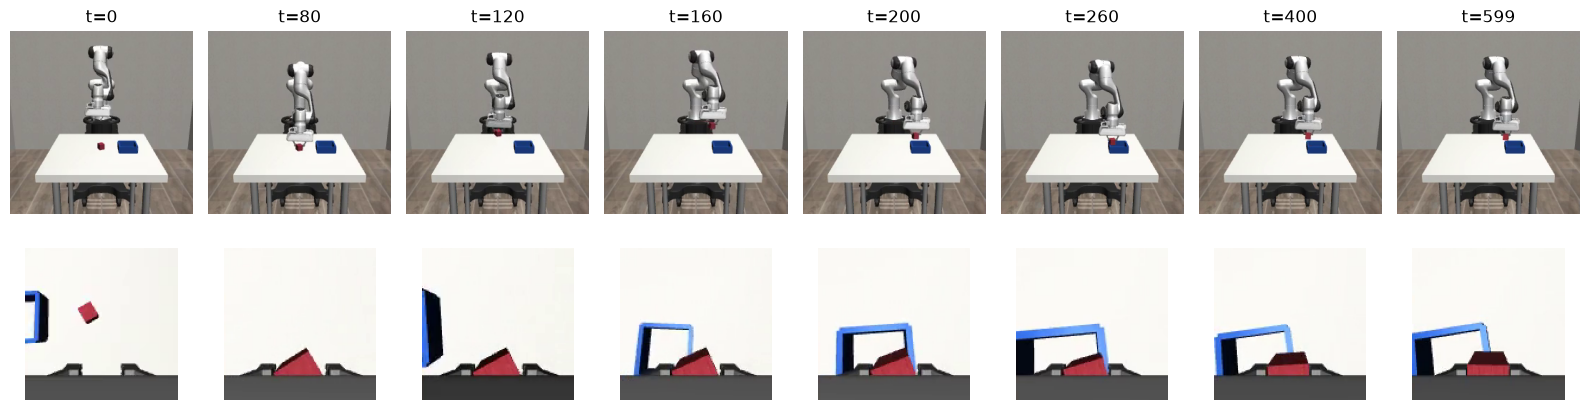

In [19]:
import imageio.v3 as iio

# step 14's film of run 2, seed 1018: the only wrong_target on record (its net is gone)
v = iio.imread(REPO / "scratch/act/wrong_target_seed1018.mp4")  # [T, H, W, 3]: wide view | top over wrist
ts = [0, 80, 120, 160, 200, 260, 400, 599]
fig, ax = plt.subplots(2, len(ts), figsize=(16, 4.6), gridspec_kw={"height_ratios": [2, 1]})
for col, t in enumerate(ts):
    ax[0, col].imshow(v[t][:, :256])  # wide view, for us
    ax[1, col].imshow(v[t][128:, 256:])  # the policy's wrist camera
    ax[0, col].set_title(f"t={t}")
for a in ax.flat:
    a.axis("off")
plt.tight_layout()
plt.show()

### step 17 — flip the weights: newest plan counts most (~6 min)

In [20]:
def rollout_newest_first(seed: int, m: float) -> tuple[bool, str, int]:
    # step 12's ensembling with the weights flipped: the NEWEST plan gets 1,
    # a plan made `age` steps ago gets exp(-m * age)
    obs = env.reset(seed=seed)
    plans = []  # (step it was made, chunk [K, 8]), oldest first
    for step in range(600):
        plans.append((step, predict(obs)))
        plans = [(s, ch) for s, ch in plans if step - s < K]
        preds = np.stack([ch[step - s] for s, ch in plans])  # [n, 8], oldest first
        age = np.array([step - s for s, _ in plans])  # [n], 0 for the plan made just now
        w = np.exp(-m * age)  # [n]
        r = env.step((w[:, None] * preds).sum(0) / w.sum())
        obs = r.observation
        if r.terminated or r.truncated:
            break
    return r.success, str(r.failure_mode), step + 1


# step 15's net, which went 20/20 with oldest-first weights
for m in [0.01, 0.1, 0.5]:
    res = [rollout_newest_first(s, m) for s in range(1000, 1020)]
    fails = Counter(mode for ok, mode, _ in res if not ok)
    print(f"newest first, m={m:<4}: {sum(ok for ok, _, _ in res):2d}/20   failures {dict(fails)}")

newest first, m=0.01: 20/20   failures {}
newest first, m=0.1 : 19/20   failures {'no_grasp': 1}
newest first, m=0.5 :  1/20   failures {'no_grasp': 18, 'dropped': 1}


### step 18 — oldest-first vs newest-first on the same 4 nets (~15 min)

In [21]:
# oldest-first (step 12) vs newest-first (step 17), both m = 0.01, on the SAME nets:
# nets swing run to run, so each is scored both ways (~15 min). Seed 0 is step 15/17: 20/20 both.
# Each net is saved so its failures can be replayed later
paired = {0: {"oldest": [True] * 20, "newest": [True] * 20}}  # seed -> {weighting: success per eval seed}
for seed in [1, 2, 3]:
    torch.manual_seed(seed)
    net = ChunkNet().to(dev)  # predict() reads this global
    train(net)
    net.eval()
    torch.save(net.state_dict(), REPO / f"scratch/act/chunknet_seed{seed}.pt")
    old = [rollout_ensemble(s, m=0.01) for s in range(1000, 1020)]
    new = [rollout_newest_first(s, m=0.01) for s in range(1000, 1020)]
    paired[seed] = {"oldest": [ok for ok, _, _ in old], "newest": [ok for ok, _, _ in new]}
    for name, res in [("oldest", old), ("newest", new)]:
        fails = {s: mode for s, (ok, mode, _) in zip(range(1000, 1020), res) if not ok}
        print(f"=== run {seed}  {name} first: {sum(ok for ok, _, _ in res)}/20   failures {fails}")

for name in ["oldest", "newest"]:
    runs = [sum(paired[s][name]) for s in [0, 1, 2, 3]]
    print(f"{name} first: {runs} -> {sum(runs)}/80")

    0  train 0.8490  val arm 0.1130  gripper 0.4590
  500  train 0.1090  val arm 0.0095  gripper 0.0806
 1000  train 0.0811  val arm 0.0074  gripper 0.0640
 1500  train 0.0712  val arm 0.0076  gripper 0.0593
 2000  train 0.0704  val arm 0.0079  gripper 0.0530
 2500  train 0.0651  val arm 0.0064  gripper 0.0532
 3000  train 0.0585  val arm 0.0060  gripper 0.0477
=== run 1  oldest first: 20/20   failures {}
=== run 1  newest first: 20/20   failures {}
    0  train 0.8460  val arm 0.1135  gripper 0.4439
  500  train 0.1065  val arm 0.0102  gripper 0.0769
 1000  train 0.0789  val arm 0.0074  gripper 0.0627
 1500  train 0.0612  val arm 0.0066  gripper 0.0493
 2000  train 0.0599  val arm 0.0067  gripper 0.0477
 2500  train 0.0560  val arm 0.0063  gripper 0.0498
 3000  train 0.0524  val arm 0.0063  gripper 0.0431
=== run 2  oldest first: 20/20   failures {}
=== run 2  newest first: 20/20   failures {}
    0  train 0.8639  val arm 0.1138  gripper 0.4503
  500  train 0.1120  val arm 0.0100  gri

## ACT's architecture, one piece at a time

### step 19 — an image becomes a grid of tokens, not 64 points

In [22]:
D = 256  # token width, the transformer's working size


def make_backbone() -> nn.Sequential:
    # BC's conv stack with one more stride-2 layer, so 128 px -> an 8x8 grid
    # (16x16 = 256 tokens per camera would make attention ~16x slower), then a
    # 1x1 conv that turns each cell's 128 features into one D-wide token
    return nn.Sequential(
        nn.Conv2d(3, 32, 5, 2, 2),  # -> [B, 32, 64, 64]
        nn.ReLU(),
        nn.Conv2d(32, 64, 3, 2, 1),  # -> [B, 64, 32, 32]
        nn.ReLU(),
        nn.Conv2d(64, 128, 3, 2, 1),  # -> [B, 128, 16, 16]
        nn.ReLU(),
        nn.Conv2d(128, 128, 3, 2, 1),  # -> [B, 128, 8, 8]
        nn.ReLU(),
        nn.Conv2d(128, D, 1),  # -> [B, D, 8, 8], one D-vector per grid cell
    )


x = IM["top"][0][:4].float() / 255  # [4, 3, 128, 128]
grid = make_backbone().to(dev)(x)  # [4, D, 8, 8]
tokens = grid.flatten(2).transpose(1, 2)  # [4, D, 64] -> [4, 64, D]: 64 tokens, one per cell
print(f"{grid.shape=}  ->  {tokens.shape=}")

grid.shape=torch.Size([4, 256, 8, 8])  ->  tokens.shape=torch.Size([4, 64, 256])


### step 20 — tell each token where its patch was: a 2-D position code

Flattening the grid in step 19 threw away row and column. Attention treats tokens as an unordered set, so without this the cube's patch and the bin's patch are just two vectors with no place.

pos.shape=torch.Size([64, 256])


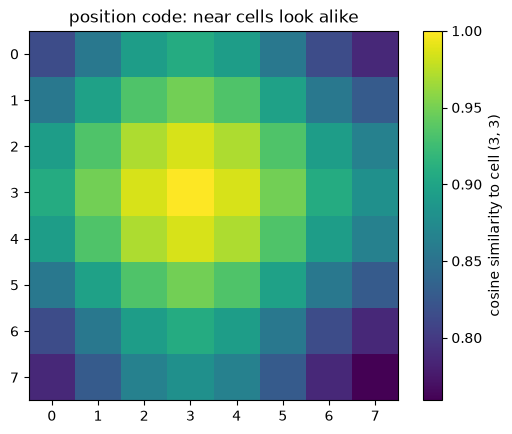

In [23]:
'''
2-D position code for an H × W grid, D numbers per cell:
    first D/2 numbers encode the row, last D/2 the column, each with the
    1-D transformer code. For position p and i = 0 … D/4 − 1:

        ωᵢ      = 10000^(−i / (D/4))                        from 1 down to ~1/10000
        code(p) = [sin(p·ω₀) … sin(p·ω_{D/4−1}),  cos(p·ω₀) … cos(p·ω_{D/4−1})]

    fast frequencies (ω ≈ 1) tell neighbouring cells apart,
    slow ones (ω ≈ 0) change smoothly across the whole grid
'''


def sinusoid_2d(h: int, w: int, d: int) -> Tensor:
    # out: [h*w, d], row-major like the flattened grid in step 19. Fixed, not learned:
    # 25 demos are too few to learn a good code for 64 cells
    q = d // 4
    omega = 10000 ** (-torch.arange(q) / q)  # [q]

    def code(n: int) -> Tensor:  # [n, d/2], the 1-D code for positions 0 .. n-1
        p = torch.arange(n)[:, None] * omega  # [n, q]
        return torch.cat([p.sin(), p.cos()], dim=-1)

    rows = code(h)[:, None, :].expand(h, w, d // 2)  # [h, w, d/2], same along a row
    cols = code(w)[None, :, :].expand(h, w, d // 2)  # [h, w, d/2], same down a column
    return torch.cat([rows, cols], dim=-1).reshape(h * w, d)


pos = sinusoid_2d(8, 8, D)  # [64, D]
print(f"{pos.shape=}")

# how alike is each cell's code to cell (row 3, col 3)'s? cosine similarity
unit = pos / pos.norm(dim=-1, keepdim=True)  # [64, D]
sim = (unit @ unit[3 * 8 + 3]).reshape(8, 8)  # [8, 8]
plt.imshow(sim, cmap="viridis")
plt.colorbar(label="cosine similarity to cell (3, 3)")
plt.title("position code: near cells look alike")
plt.show()

### step 21 — one observation as one sequence of tokens

Each patch token = what's in it + where it is (step 20) + which camera. The state becomes one more token.

In [24]:
# the pieces the model will own; built loose here just to see the shapes
backbones = nn.ModuleDict({cam: make_backbone() for cam in cams}).to(dev)  # one per camera
cam_tag = nn.Parameter(torch.randn(len(cams), D, device=dev) * 0.02)  # [2, D], learned: which camera
state_in = nn.Linear(8, D).to(dev)  # the 8 state numbers -> one D-wide token

i = torch.arange(4, device=dev)  # 4 train frames
parts = [state_in((Xtr[i] - s_mean) / s_std)[:, None]]  # [4, 1, D], the state as one token
for k, cam in enumerate(cams):
    im = (IM[cam][0][i].float() / 255 - im_stats[cam][0]) / im_stats[cam][1]  # [4, 3, H, W]
    tok = backbones[cam](im).flatten(2).transpose(1, 2)  # [4, 64, D], what is in each patch
    parts.append(tok + pos.to(dev) + cam_tag[k])  # + where it is + which camera
seq = torch.cat(parts, dim=1)  # [4, 1 + 64 + 64, D]
print([tuple(p.shape) for p in parts], "->", tuple(seq.shape))

[(4, 1, 256), (4, 64, 256), (4, 64, 256)] -> (4, 129, 256)


### step 22 — transformer encoder: every token looks at every other

In [25]:
# 2 layers of: every token attends to all 129 (8 heads), then a per-token MLP of width 1024
layer = nn.TransformerEncoderLayer(D, nhead=8, dim_feedforward=1024, dropout=0.1, batch_first=True)
encoder = nn.TransformerEncoder(layer, num_layers=2, enable_nested_tensor=False).to(dev)

encoder.eval()  # dropout off, so the check below sees only the mixing
with torch.no_grad():
    out = encoder(seq)  # [4, 129, D] -> [4, 129, D], same shape
    print(f"{seq.shape=} -> {out.shape=}")

    # does information flow between tokens? change ONLY the state token (index 0)
    seq2 = seq.clone()
    seq2[:, 0] += 1.0
    before = (seq2 - seq)[:, 1:].abs().mean()  # the 128 image tokens, going in
    after = (encoder(seq2) - out)[:, 1:].abs().mean()  # the same tokens, coming out
    print(f"image tokens changed by: {before:.3f} going in, {after:.3f} coming out")

seq.shape=torch.Size([4, 129, 256]) -> out.shape=torch.Size([4, 129, 256])
image tokens changed by: 0.000 going in, 0.005 coming out
